In [1]:
import sys
sys.executable

'/cs/student/projects1/aibh/2024/gcosta/venv/bin/python'

In [2]:
# from one.api import ONE
import matplotlib.pyplot as plt
import numpy as np
import sys
import os
import seaborn as sns
from rastermap import Rastermap
from utils.calcium_raster import plot_calcium_raster

import h5py
from utils.load_meso_session import MesoscopeSession

from one.api import ONE
one = ONE()

SESSION_INDEX = 0


In [3]:
session = MesoscopeSession.from_eid(one, "5ea6bb9b-6163-4e8a-816b-efe7002666b0")
activity, timestamps = session.get_dff_activity_matrix()

Loading session from ONE


In [4]:

model = Rastermap(n_clusters=100, # number of clusters to compute
                  n_PCs=200, # number of PCs
                  locality=0.1, # locality in sorting is low here to get more global sorting (this is a value from 0-1)
                  time_lag_window=5, # use future timepoints to compute correlation
                  grid_upsample=10, # default value, 10 is good for large recordings
                  ).fit(activity.T)

2025-09-06 20:18:35,456 [INFO] normalizing data across axis=1
2025-09-06 20:18:36,093 [INFO] projecting out mean along axis=0
2025-09-06 20:18:36,908 [INFO] data normalized, 1.45sec
2025-09-06 20:18:36,908 [INFO] sorting activity: 11393 valid samples by 22074 timepoints
2025-09-06 20:18:47,790 [INFO] n_PCs = 200 computed, 12.33sec
2025-09-06 20:18:48,660 [INFO] 100 clusters computed, time 13.20sec
2025-09-06 20:18:56,077 [INFO] clusters sorted, time 20.62sec
2025-09-06 20:18:56,239 [INFO] clusters upsampled, time 20.78sec
2025-09-06 20:18:56,528 [INFO] rastermap complete, time 21.07sec


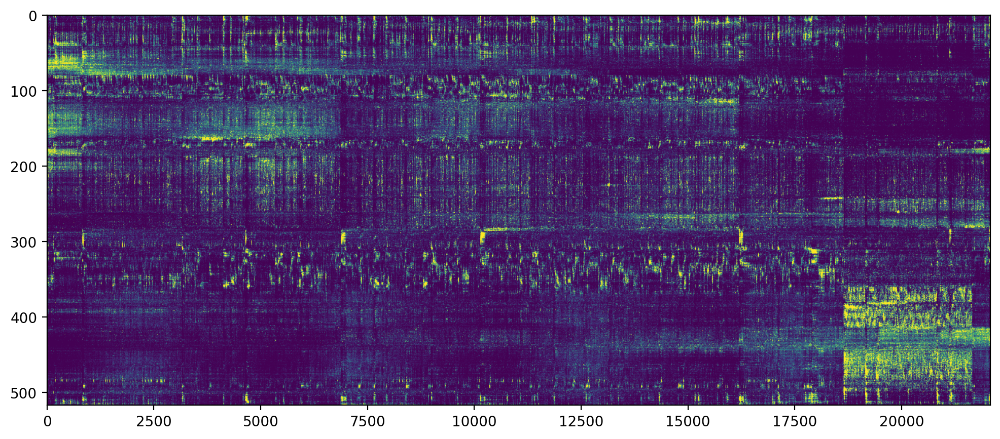

In [5]:
y = model.embedding
isort = model.isort
X_embedding = model.X_embedding

fig = plt.figure(figsize=(12,5), dpi=200)
ax = fig.add_subplot(111)
ax.imshow(X_embedding, vmin=-0.1, vmax=2.6, cmap="viridis", aspect="auto")

In [6]:
last_stimOff_secs = session.stimOff_times[-1]  # trial_phase is the last feature
print(last_stimOff_secs)
last_stimoff_timestep_idx = np.searchsorted(timestamps, last_stimOff_secs, side='right') - 1
print(last_stimoff_timestep_idx)

3667.244
18308


# EXP 2 Passive Task

1470.0


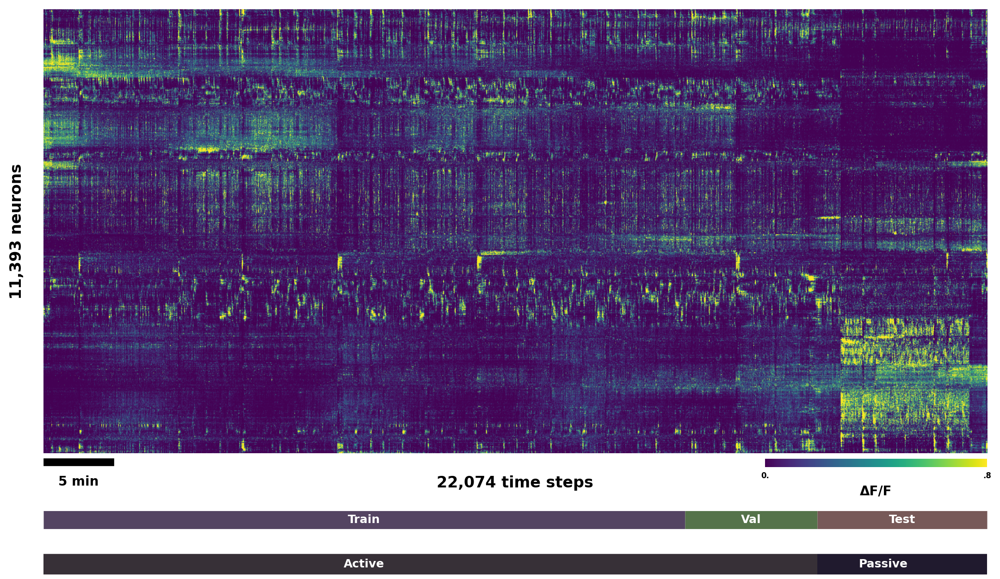

In [40]:
import matplotlib.pyplot as plt
import numpy as np
from mpl_toolkits.axes_grid1 import make_axes_locatable

plt.rcParams['font.weight'] = 'bold'
plt.rcParams['font.size'] = 10

# Your data
num_neurons = activity.shape[1]
embedding_min = -0.1
embedding_max = 2.6

# Get dimensions
_, n_timesteps = X_embedding.shape
# total_time_minutes = n_timesteps / 4.9
total_time_minutes = session.duration_seconds / 60

# Calculate 5-minute scale bar width in axes coordinates
# minutes_per_timestep = total_time_minutes / n_timesteps
# timesteps_per_5min = 5 / minutes_per_timestep
timesteps_per_5min = 4.9 * 60 * 5
print(timesteps_per_5min)
scale_bar_width = timesteps_per_5min / n_timesteps  # Convert to fraction of plot width

# Create figure with manual positioning
fig = plt.figure(figsize=(12, 6), dpi=200)
ax = fig.add_axes((0.08, 0.15, 0.85, 0.8))  # (left, bottom, width, height) - leave space for labels

# Main raster plot
im = ax.imshow(X_embedding, vmin=embedding_min, vmax=embedding_max, cmap="viridis", aspect="auto")

# Remove default ticks and labels
ax.set_xticks([])
ax.set_yticks([])

ax.text(-0.02, 0.5, f'{num_neurons:,} neurons', transform=ax.transAxes, 
        rotation=90, ha='right', va='center', fontweight='bold', fontsize=12)

# Add 5-minute scale bar (aligned with left edge of image data)
# Small offset to align with actual image data start
image_left_offset = 0.004  # Fine-tune this to align with image left edge
ax.plot([image_left_offset, image_left_offset + scale_bar_width], [-0.02, -0.02], 'k-', 
        linewidth=6, clip_on=False, transform=ax.transAxes)
ax.text(image_left_offset + scale_bar_width/2, -0.05, '5 min', 
        transform=ax.transAxes, ha='center', va='top', fontweight='bold', fontsize=10)

# Add timestep count in bottom center
ax.text(0.5, -0.05, f'{n_timesteps:,} time steps', transform=ax.transAxes, 
        ha='center', va='top', fontweight='bold', fontsize=12)

# Create small colorbar aligned with right edge of image
# Calculate position to align with the right edge of the main axes
ax_pos = ax.get_position()
cbar_width = 0.2
cbar_height = 0.015
cbar_left = ax_pos.x1 - cbar_width  # Right edge of main axes minus colorbar width
cbar_ax = fig.add_axes((cbar_left, 0.125 , cbar_width, cbar_height))  # (left, bottom, width, height)
cbar = plt.colorbar(im, cax=cbar_ax, ticks=[embedding_min, embedding_max], orientation='horizontal')

cbar.outline.set_visible(False)
cbar.ax.tick_params(labelsize=6, width=0, length=0)  # Remove tick marks
cbar.ax.set_xlabel('ΔF/F', fontweight='bold', fontsize=10)
cbar.ax.set_xticklabels(['0.', '.8'])

# Remove colorbar border

# Remove spines and clean up
for spine in ax.spines.values():
    spine.set_visible(False)
    
# Define split proportions and colors
train_end = 0.68
val_end = 0.82  # train_end + 0.1
colors = {'train': "#544462", 'val': "#55734A", 'test': "#775958"} # Blue, Yellow, Green

# Define position and height for the bar and its text
bar_y_pos = -0.15
text_y_pos = -0.15
bar_height = 14  # Use linewidth to control the bar's thickness

# Draw Train bar segment (70%)
ax.plot([0, train_end], [bar_y_pos, bar_y_pos], color=colors['train'],
        linewidth=bar_height, solid_capstyle='butt',
        transform=ax.transAxes, clip_on=False)
ax.text(train_end / 2, text_y_pos, 'Train', color='white',
        transform=ax.transAxes, ha='center', va='center', fontweight='bold', fontsize=9)

# Draw Validation bar segment (10%)
ax.plot([train_end, val_end], [bar_y_pos, bar_y_pos], color=colors['val'],
        linewidth=bar_height, solid_capstyle='butt',
        transform=ax.transAxes, clip_on=False)
ax.text(train_end + (val_end - train_end) / 2, text_y_pos, 'Val', color="white",
        transform=ax.transAxes, ha='center', va='center', fontweight='bold', fontsize=9)

# Draw Test bar segment (20%)
ax.plot([val_end, 1.0], [bar_y_pos, bar_y_pos], color=colors['test'],
        linewidth=bar_height, solid_capstyle='butt',
        transform=ax.transAxes, clip_on=False)
ax.text(val_end + (1.0 - val_end) / 2, text_y_pos, 'Test', color='white',
        transform=ax.transAxes, ha='center', va='center', fontweight='bold', fontsize=9)


        
        
bar_y_pos = -0.25
text_y_pos = -0.25
bar_height = 16  # Use linewidth to control the bar's thickness        

# Draw Train bar segment (70%)
ax.plot([0, val_end], [bar_y_pos, bar_y_pos], color="#373037",
        linewidth=bar_height, solid_capstyle='butt',
        transform=ax.transAxes, clip_on=False)
ax.text(train_end / 2, text_y_pos, 'Active', color='white',
        transform=ax.transAxes, ha='center', va='center', fontweight='bold', fontsize=9)

# Draw Train bar segment (70%)
ax.plot([val_end, 1.0], [bar_y_pos, bar_y_pos], color="#201A2E",
        linewidth=bar_height, solid_capstyle='butt',
        transform=ax.transAxes, clip_on=False)
ax.text(val_end + .07, text_y_pos, 'Passive', color='white',
        transform=ax.transAxes, ha='center', va='center', fontweight='bold', fontsize=9)


# Save without tight_layout to avoid warning
plt.savefig("../FIGURES/Activity_Traces_Behavioral.png", bbox_inches='tight', pad_inches=0.1)

plt.show()

# EXP 1 Active Task

In [44]:
X_embedding_2 = X_embedding[:, 0:last_stimoff_timestep_idx]

1470.0


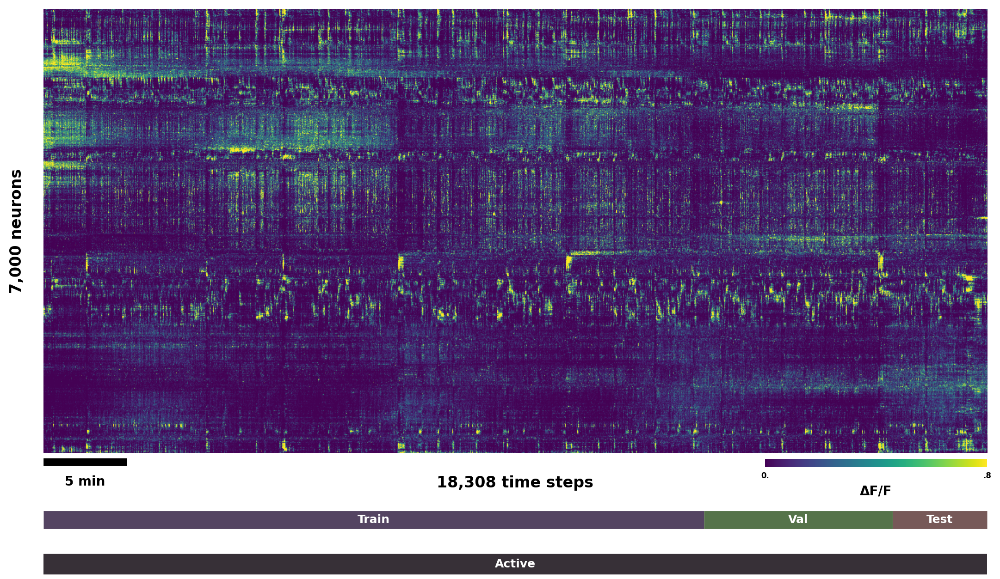

In [48]:
import matplotlib.pyplot as plt
import numpy as np
from mpl_toolkits.axes_grid1 import make_axes_locatable

plt.rcParams['font.weight'] = 'bold'
plt.rcParams['font.size'] = 10

# Your data
num_neurons =  7000 #activity.shape[1]
embedding_min = -0.1
embedding_max = 2.6

# Get dimensions
_, n_timesteps = X_embedding_2.shape
# total_time_minutes = n_timesteps / 4.9
total_time_minutes = session.duration_seconds / 60

# Calculate 5-minute scale bar width in axes coordinates
# minutes_per_timestep = total_time_minutes / n_timesteps
# timesteps_per_5min = 5 / minutes_per_timestep
timesteps_per_5min = 4.9 * 60 * 5
print(timesteps_per_5min)
scale_bar_width = timesteps_per_5min / n_timesteps  # Convert to fraction of plot width

# Create figure with manual positioning
fig = plt.figure(figsize=(12, 6), dpi=200)
ax = fig.add_axes((0.08, 0.15, 0.85, 0.8))  # (left, bottom, width, height) - leave space for labels

# Main raster plot
im = ax.imshow(X_embedding_2, vmin=embedding_min, vmax=embedding_max, cmap="viridis", aspect="auto")

# Remove default ticks and labels
ax.set_xticks([])
ax.set_yticks([])

ax.text(-0.02, 0.5, f'{num_neurons:,} neurons', transform=ax.transAxes, 
        rotation=90, ha='right', va='center', fontweight='bold', fontsize=12)

# Add 5-minute scale bar (aligned with left edge of image data)
# Small offset to align with actual image data start
image_left_offset = 0.004  # Fine-tune this to align with image left edge
ax.plot([image_left_offset, image_left_offset + scale_bar_width], [-0.02, -0.02], 'k-', 
        linewidth=6, clip_on=False, transform=ax.transAxes)
ax.text(image_left_offset + scale_bar_width/2, -0.05, '5 min', 
        transform=ax.transAxes, ha='center', va='top', fontweight='bold', fontsize=10)

# Add timestep count in bottom center
ax.text(0.5, -0.05, f'{n_timesteps:,} time steps', transform=ax.transAxes, 
        ha='center', va='top', fontweight='bold', fontsize=12)

# Create small colorbar aligned with right edge of image
# Calculate position to align with the right edge of the main axes
ax_pos = ax.get_position()
cbar_width = 0.2
cbar_height = 0.015
cbar_left = ax_pos.x1 - cbar_width  # Right edge of main axes minus colorbar width
cbar_ax = fig.add_axes((cbar_left, 0.125 , cbar_width, cbar_height))  # (left, bottom, width, height)
cbar = plt.colorbar(im, cax=cbar_ax, ticks=[embedding_min, embedding_max], orientation='horizontal')

cbar.outline.set_visible(False)
cbar.ax.tick_params(labelsize=6, width=0, length=0)  # Remove tick marks
cbar.ax.set_xlabel('ΔF/F', fontweight='bold', fontsize=10)
cbar.ax.set_xticklabels(['0.', '.8'])

# Remove colorbar border

# Remove spines and clean up
for spine in ax.spines.values():
    spine.set_visible(False)
    
# Define split proportions and colors
train_end = 0.7
val_end = 0.9  # train_end + 0.1
colors = {'train': "#544462", 'val': "#55734A", 'test': "#775958"} # Blue, Yellow, Green

# Define position and height for the bar and its text
bar_y_pos = -0.15
text_y_pos = -0.15
bar_height = 14  # Use linewidth to control the bar's thickness

# Draw Train bar segment (70%)
ax.plot([0, train_end], [bar_y_pos, bar_y_pos], color=colors['train'],
        linewidth=bar_height, solid_capstyle='butt',
        transform=ax.transAxes, clip_on=False)
ax.text(train_end / 2, text_y_pos, 'Train', color='white',
        transform=ax.transAxes, ha='center', va='center', fontweight='bold', fontsize=9)

# Draw Validation bar segment (10%)
ax.plot([train_end, val_end], [bar_y_pos, bar_y_pos], color=colors['val'],
        linewidth=bar_height, solid_capstyle='butt',
        transform=ax.transAxes, clip_on=False)
ax.text(train_end + (val_end - train_end) / 2, text_y_pos, 'Val', color="white",
        transform=ax.transAxes, ha='center', va='center', fontweight='bold', fontsize=9)

# Draw Test bar segment (20%)
ax.plot([val_end, 1.0], [bar_y_pos, bar_y_pos], color=colors['test'],
        linewidth=bar_height, solid_capstyle='butt',
        transform=ax.transAxes, clip_on=False)
ax.text(val_end + (1.0 - val_end) / 2, text_y_pos, 'Test', color='white',
        transform=ax.transAxes, ha='center', va='center', fontweight='bold', fontsize=9)


        
        
bar_y_pos = -0.25
text_y_pos = -0.25
bar_height = 16  # Use linewidth to control the bar's thickness        

ax.plot([0, 1], [bar_y_pos, bar_y_pos], color="#373037",
        linewidth=bar_height, solid_capstyle='butt',
        transform=ax.transAxes, clip_on=False)
ax.text(1 / 2, text_y_pos, 'Active', color='white',
        transform=ax.transAxes, ha='center', va='center', fontweight='bold', fontsize=9)

# ax.plot([val_end, 1.0], [bar_y_pos, bar_y_pos], color="#201A2E",
#         linewidth=bar_height, solid_capstyle='butt',
#         transform=ax.transAxes, clip_on=False)
# ax.text(val_end + .07, text_y_pos, 'Passive', color='white',
#         transform=ax.transAxes, ha='center', va='center', fontweight='bold', fontsize=9)


# Save without tight_layout to avoid warning
plt.savefig("../FIGURES/Activity_Traces_Variates.png", bbox_inches='tight', pad_inches=0.1)

plt.show()

In [49]:
preprocessed_session = MesoscopeSession.from_preprocessed("/cs/student/projects1/aibh/2024/gcosta/mpci_data/session_5ea6bb9b-6163-4e8a-816b-efe7002666b0_7000.h5")
activity_preprocessed, timestamps_preprocessed = preprocessed_session.get_preprocessed_data()

Preprocessed session loaded from /cs/student/projects1/aibh/2024/gcosta/mpci_data/session_5ea6bb9b-6163-4e8a-816b-efe7002666b0_7000.h5
Shape: (18309, 7000) (time_points x neurons)
EID: 5ea6bb9b-6163-4e8a-816b-efe7002666b0, Subject: SP063


In [50]:
def encode_stimulus_types(session, timestamps):
    """
    Create one-hot encoding for stimulus types based on contrast combinations.
    
    Stimulus types are defined by contrast combinations:
    - 0: Catch trials - (left=0 & right=NaN) OR (left=NaN & right=0) - no stimulus, animal uses prior knowledge
    - 1-4: Left side stimuli (100%, 25%, 12.5%, 6.25%) with right=NaN
    - 5-8: Right side stimuli (100%, 25%, 12.5%, 6.25%) with left=NaN
    
    Args:
        session: MesoscopeSession object
        timestamps: 1D array of neural timestamps to encode [n_timepoints]
        
    Returns:
        np.ndarray: One-hot encoded stimulus types [n_timepoints, 9]
    """
    # Define contrast values (excluding 0% as it's catch trial)
    contrast_values = [1.0, 0.25, 0.125, 0.0625]  # 100%, 25%, 12.5%, 6.25%
    
    # Initialize one-hot matrix
    n_timepoints = len(timestamps)
    stimulus_encoding = np.zeros((n_timepoints, 9), dtype=np.float32)
    
    # For each trial, find which timepoints fall within stimulus presentation
    for trial_idx in range(len(session.stimOn_times)):
        stim_on = session.stimOn_times[trial_idx]
        stim_off = session.stimOff_times[trial_idx]
        
        # Skip trials with NaN timing
        if np.isnan(stim_on) or np.isnan(stim_off):
            continue
        
        # Find timepoints within this stimulus period
        mask = (timestamps >= stim_on) & (timestamps <= stim_off)
        
        if not np.any(mask):
            continue
        
        # Get contrasts for this trial
        left_contrast = session.contrastLeft[trial_idx]
        right_contrast = session.contrastRight[trial_idx]
        
        # Keep NaN values as they indicate catch trials
        # Don't convert to 0.0 yet
        
        # Determine stimulus type
        stimulus_type = _get_stimulus_type(left_contrast, right_contrast, contrast_values)
        
        # Set one-hot encoding for this time period
        stimulus_encoding[mask, stimulus_type] = 1.0
    
    return stimulus_encoding

def _get_stimulus_type(left_contrast, right_contrast, contrast_values):
    """
    Map contrasts to stimulus type index.
    
    Stimulus types:
    0: Catch trial (left=0 & right=NaN) OR (left=NaN & right=0) - no stimulus
    1-4: Left stimuli (1.0, 0.25, 0.125, 0.0625) with right=NaN
    5-8: Right stimuli (1.0, 0.25, 0.125, 0.0625) with left=NaN
    
    Returns:
        int: Stimulus type (0-8)
    """
    # Catch trials: no stimulus on either side
    if (left_contrast == 0.0 and np.isnan(right_contrast)) or (np.isnan(left_contrast) and right_contrast == 0.0):
        return 0
    
    # Left stimulus (right = NaN, left has contrast > 0)
    if np.isnan(right_contrast) and not np.isnan(left_contrast) and left_contrast > 0.0:
        try:
            contrast_idx = contrast_values.index(left_contrast)
            return 1 + contrast_idx  # Types 1-4
        except ValueError:
            # Find closest match for floating point precision issues
            distances = [abs(left_contrast - cv) for cv in contrast_values]
            closest_idx = distances.index(min(distances))
            return 1 + closest_idx
    
    # Right stimulus (left = NaN, right has contrast > 0)  
    if np.isnan(left_contrast) and not np.isnan(right_contrast) and right_contrast > 0.0:
        try:
            contrast_idx = contrast_values.index(right_contrast)
            return 5 + contrast_idx  # Types 5-8
        except ValueError:
            # Find closest match for floating point precision issues
            distances = [abs(right_contrast - cv) for cv in contrast_values]
            closest_idx = distances.index(min(distances))
            return 5 + closest_idx
    
    # Default to catch trial if no clear match
    return 0

# Test the encoding function
stimulus_onehot = encode_stimulus_types(preprocessed_session, timestamps_preprocessed)
# print(f"\n=== Results ===")
# print(f"Stimulus encoding shape: {stimulus_onehot.shape}")
# print(f"Timestamps shape: {timestamps.shape}")
# print(f"Unique stimulus types present: {np.where(stimulus_onehot.sum(axis=0) > 0)[0]}")
# print(f"Total timepoints with stimulus: {stimulus_onehot.sum()}")
# print(f"Proportion of time with stimulus: {stimulus_onehot.sum() / len(timestamps):.3f}")

# print(stimulus_onehot[0:10])
# # Check contrast distribution
# print(f"\n=== Contrast distribution ===")
# left_unique = np.unique(preprocessed_session.contrastLeft[~np.isnan(preprocessed_session.contrastLeft)])
# right_unique = np.unique(preprocessed_session.contrastRight[~np.isnan(preprocessed_session.contrastRight)])
# print(f"Unique left contrasts: {left_unique}")
# print(f"Unique right contrasts: {right_unique}")

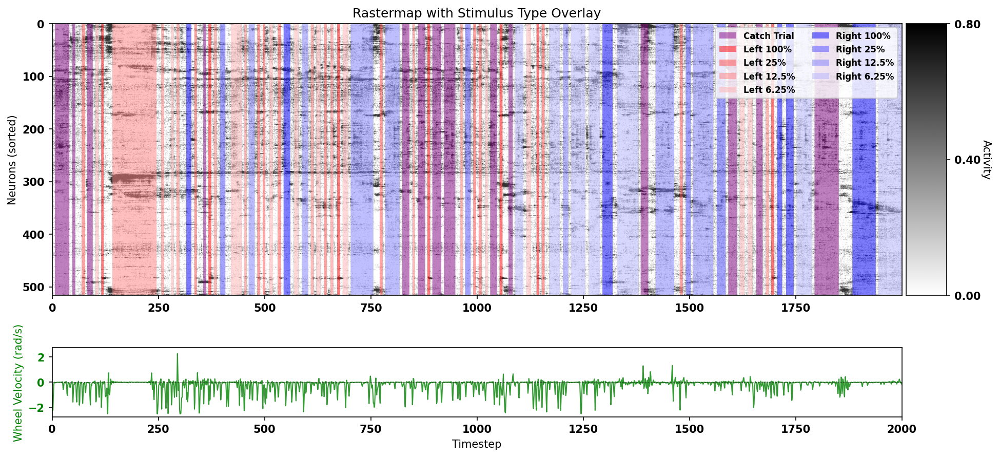

Velocity stats for window:
  Range: -2.500 to 2.263 rad/s
  Non-zero samples: 2000/2000 (100.0%)
  Mean |velocity|: 0.277 rad/s


In [67]:
xmin_idx = 10000
xmax_idx = 12000


def plot_wheel_velocity(ax, aligned_wheel_velocity, timestamps, xmin_idx, xmax_idx):
    """Plot wheel velocity trace as a single continuous line"""
    # Get wheel velocity for the time window
    wheel_vel_window = aligned_wheel_velocity[xmin_idx:xmax_idx]
    time_indices = np.arange(len(wheel_vel_window))
    
    # Plot velocity as a single continuous line
    ax.plot(time_indices, wheel_vel_window, color='green', linewidth=1, alpha=0.8)
    
    # Add horizontal line at zero for reference
    ax.axhline(y=0, color='black', linewidth=0.5, alpha=0.5, linestyle='--')
    
    ax.set_ylabel('Wheel Velocity (rad/s)', color='green')
    ax.tick_params(axis='y', labelcolor='green')
    ax.set_xlim(0, len(wheel_vel_window))
    
    # Set y-axis limits to show velocity range clearly
    vel_max = np.max(np.abs(wheel_vel_window))
    if vel_max > 0:
        ax.set_ylim(-vel_max*1.1, vel_max*1.1)
    else:
        ax.set_ylim(-0.1, 0.1)  # Show small range if all zeros


def create_stimulus_overlay(stimulus_onehot, xmin_idx, xmax_idx):
    """Create a colored overlay for stimulus types"""
    # Get stimulus data for the time window
    stim_window = stimulus_onehot[xmin_idx:xmax_idx]
    
    # Define colors for each stimulus type
    # 0: Catch trials (purple)
    # 1-4: Left stimuli (different shades of red)
    # 5-8: Right stimuli (different shades of blue)
    colors = [
        [0.5, 0, 0.5, 0.5],  # 0: Purple (catch trials - no stimulus)
        [1, 0, 0, 0.5],      # 1: Left 100% - dark red
        [1, 0.3, 0.3, 0.5],  # 2: Left 25% - medium red
        [1, 0.5, 0.5, 0.5],  # 3: Left 12.5% - light red
        [1, 0.7, 0.7, 0.5],  # 4: Left 6.25% - very light red
        [0, 0, 1, 0.5],      # 5: Right 100% - dark blue
        [0.3, 0.3, 1, 0.5],  # 6: Right 25% - medium blue
        [0.5, 0.5, 1, 0.5],  # 7: Right 12.5% - light blue
        [0.7, 0.7, 1, 0.5]   # 8: Right 6.25% - very light blue
    ]
    
    # Convert one-hot to stimulus type indices
    stim_types = np.argmax(stim_window, axis=1)
    
    # Create RGB overlay
    nn = X_embedding.shape[0]  # Number of neurons
    overlay = np.zeros((nn, len(stim_types), 4))  # RGBA
    
    for t, stim_type in enumerate(stim_types):
        if np.any(stim_window[t]):  # Only color if there's a stimulus
            overlay[:, t] = colors[stim_type]
    
    return overlay

# Create figure for stimulus-colored rastermap with wheel velocity
fig = plt.figure(figsize=(15, 8), dpi=150)
grid = plt.GridSpec(12, 20, figure=fig, wspace=0.1, hspace=0.4)


# Plot rastermap (keep original scaling)
ax_raster = plt.subplot(grid[2:9, :-1])
ax_raster.imshow(X_embedding[:, xmin_idx:xmax_idx], cmap="gray_r", vmin=-.25, vmax=2.5, aspect="auto", alpha=0.8)

# Create and overlay stimulus colors
stim_overlay = create_stimulus_overlay(stimulus_onehot, xmin_idx, xmax_idx)
ax_raster.imshow(stim_overlay, aspect="auto")

ax_raster.set_ylabel("Neurons (sorted)")
ax_raster.set_title("Rastermap with Stimulus Type Overlay")

ax_cbar = plt.subplot(grid[2:9, -1])
activity_gradient = np.linspace(0.8, 0, X_embedding.shape[0])[:, np.newaxis]  # High at top
ax_cbar.imshow(activity_gradient, cmap="gray_r", aspect="auto", vmin=0, vmax=0.8)
ax_cbar.yaxis.set_label_position("right")
ax_cbar.set_ylabel("Activity", rotation=270, labelpad=10)
ax_cbar.set_yticks([0, X_embedding.shape[0]//2, X_embedding.shape[0]-1])
ax_cbar.set_yticklabels(['0.80', '0.40', '0.00'])
ax_cbar.set_xticks([])
ax_cbar.yaxis.tick_right()

# ax_pos = ax.get_position()
# cbar_width = 0.2
# cbar_height = 0.015
# cbar_left = ax_pos.x1 - cbar_width  # Right edge of main axes minus colorbar width
# cbar_ax = fig.add_axes((cbar_left, 0.125 , cbar_width, cbar_height))  # (left, bottom, width, height)
# cbar = plt.colorbar(im, cax=cbar_ax, ticks=[embedding_min, embedding_max], orientation='horizontal')

# cbar.outline.set_visible(False)
# cbar.ax.tick_params(labelsize=6, width=0, length=0)  # Remove tick marks
# cbar.ax.set_xlabel('ΔF/F', fontweight='bold', fontsize=10)
# cbar.ax.set_xticklabels(['0.', '.8'])


# Plot wheel velocity below the rastermap (bigger vertical space)
ax_wheel = plt.subplot(grid[10:12, :-1])
plot_wheel_velocity(ax_wheel, preprocessed_session.aligned_wheel_velocity, timestamps, xmin_idx, xmax_idx)
ax_wheel.set_xlabel("Timestep")

# Create legend for stimulus types
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor=(0.5, 0, 0.5, 0.5), label='Catch Trial'),
    Patch(facecolor=(1, 0, 0, 0.5), label='Left 100%'),
    Patch(facecolor=(1, 0.3, 0.3, 0.5), label='Left 25%'),
    Patch(facecolor=(1, 0.5, 0.5, 0.5), label='Left 12.5%'),
    Patch(facecolor=(1, 0.7, 0.7, 0.5), label='Left 6.25%'),
    Patch(facecolor=(0, 0, 1, 0.5), label='Right 100%'),
    Patch(facecolor=(0.3, 0.3, 1, 0.5), label='Right 25%'),
    Patch(facecolor=(0.5, 0.5, 1, 0.5), label='Right 12.5%'),
    Patch(facecolor=(0.7, 0.7, 1, 0.5), label='Right 6.25%')
]
ax_raster.legend(handles=legend_elements, loc='upper right', fontsize=8, ncol=2)

plt.show()

# Print velocity statistics for this window
vel_window = preprocessed_session.aligned_wheel_velocity[xmin_idx:xmax_idx]
print(f"Velocity stats for window:")
print(f"  Range: {np.min(vel_window):.3f} to {np.max(vel_window):.3f} rad/s")
print(f"  Non-zero samples: {np.sum(vel_window != 0)}/{len(vel_window)} ({100*np.sum(vel_window != 0)/len(vel_window):.1f}%)")
print(f"  Mean |velocity|: {np.mean(np.abs(vel_window)):.3f} rad/s")
